# B-8802B — como a base separa a bomba ligada da desligada, e quantas distribuições existem

Dado de jan/2025 a ago/2026 (1 min), o mesmo do bundle B-8802B-2025. Perguntas:
1. Como o filtro tira os momentos com a bomba desligada, e quanto dado cada passo remove?
2. Com a bomba ligada, cada sensor tem **uma** distribuição ou **duas**? Duas podem indicar fases operacionais diferentes.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

SAVE_PLOTS = False
ROOT = Path.cwd()
while not (ROOT / "deploy_v2").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
D = ROOT / "deploy_v2" / "Transpetro"
sys.path.insert(0, str(D))
import simpred_inference as si

EQUIP = "B-8802B"
B = next((D / "B-8802B-2025" / "modelos").iterdir())
raw = si.carregar_dados(si.achar_csv(D / "B-8802B-2025" / "dados", "data_2025-01-01_2026-08-10_raw.csv"))
SENS = ["Pressão Descarga", "Pressão Sucção", "Vibração Bomba LA", "Vibração Bomba LNA",
        "Temperatura Bomba LA", "Temperatura Bomba LNA", "Temperatura Motor LA", "Temperatura Motor LNA"]
print(f"{len(raw):,} linhas de 1 min, {raw.index.min():%d/%m/%Y} a {raw.index.max():%d/%m/%Y}")

845,218 linhas de 1 min, 01/01/2025 a 10/08/2026


## 1. O filtro, passo a passo (o mesmo `pipeline.json` do bundle em produção)

| Passo | O que faz |
|---|---|
| `remove_sensor_errors` | valor 0,0 vira "sem dado" (código de erro do sensor) |
| `filter_running` | fica só com **pressão de descarga > 35 bar**: é o critério de bomba ligada |
| `resample` + `ffill` | grade de 5 min, com o último valor; preenche até 20 min de buraco |
| `remove_transients` | tira os **90 min depois de cada partida** (buraco > 30 min = bomba voltou a ligar) |
| `remove_regime_transients` | tira 90 min depois de uma manobra brusca (sucção ±2,4 bar ou descarga ±4,8 bar em 15 min) |
| `remove_frozen_segments` | tira trechos em que 3 ou mais sensores ficaram com o mesmo valor por 12 h (falha de aquisição) |

In [2]:
steps = json.loads((B / "pipeline.json").read_text())
p = {s["step"]: {k: v for k, v in s.items() if k != "step"} for s in steps}
etapas = [("bruto (1 min)", raw)]
x = si.remove_sensor_errors(raw.copy(), **p["remove_sensor_errors"])
x = si.filter_running(x, **p["filter_running"]);                    etapas.append(("bomba ligada (descarga > 35 bar)", x))
x = si.ffill(si.resample(x, **p["resample"]), **p["ffill"]);        etapas.append(("grade de 5 min", x))
x = si.remove_transients(x, **p["remove_transients"]);              etapas.append(("sem os 90 min após partida", x))
x = si.remove_regime_transients(x, **p["remove_regime_transients"]); etapas.append(("sem manobras bruscas", x))
x = si.remove_frozen_segments(x);                                    etapas.append(("sem dado congelado", x))
filt = x
horas = [len(d) * (1 if i == 0 or i == 1 else 5) / 60 for i, (_, d) in enumerate(etapas)]
pd.DataFrame({"etapa": [n for n, _ in etapas], "linhas": [len(d) for _, d in etapas],
              "horas": np.round(horas).astype(int)})

,etapa,linhas,horas
0,bruto (1 min),845218,14087
1,bomba ligada (descarga > 35 bar),733243,12221
2,grade de 5 min,147442,12287
3,sem os 90 min após partida,145180,12098
4,sem manobras bruscas,139264,11605
5,sem dado congelado,134520,11210


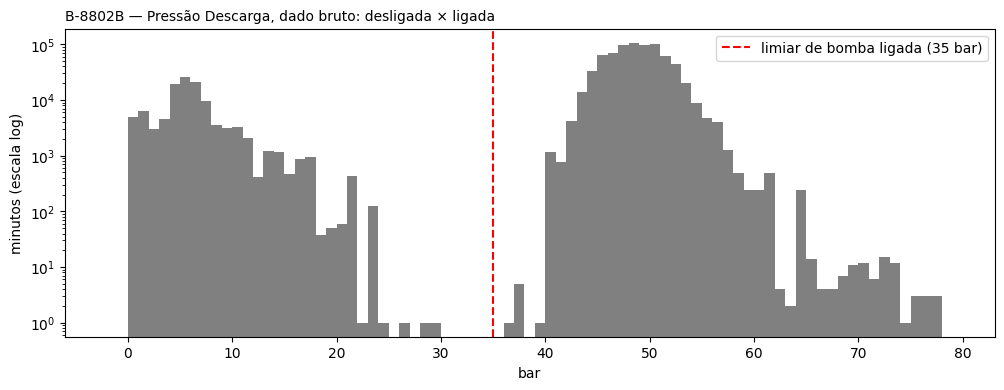

minutos com descarga entre 25 e 40 bar: 10


In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
b = np.arange(-2, 80, 1)
ax.hist(raw["Pressão Descarga"], bins=b, color="gray")
ax.axvline(35, color="red", ls="--", label="limiar de bomba ligada (35 bar)")
ax.set_yscale("log"); ax.set_xlabel("bar"); ax.set_ylabel("minutos (escala log)")
ax.set_title(f"{EQUIP} — Pressão Descarga, dado bruto: desligada × ligada", loc="left", fontsize=10)
ax.legend(); plt.show()
print("minutos com descarga entre 25 e 40 bar:", int(raw["Pressão Descarga"].between(25, 40).sum()))

A pressão de descarga tem **dois grupos bem separados**: de 0 a cerca de 25 bar (bomba parada) e de 40 a 60 bar (bomba ligada). Entre 25 e 40 bar praticamente não há dado. O limiar de 35 bar cai no vazio entre os dois, então o filtro não corta operação real nem deixa passar parada.

## 2. Bruto × filtrado, sensor por sensor

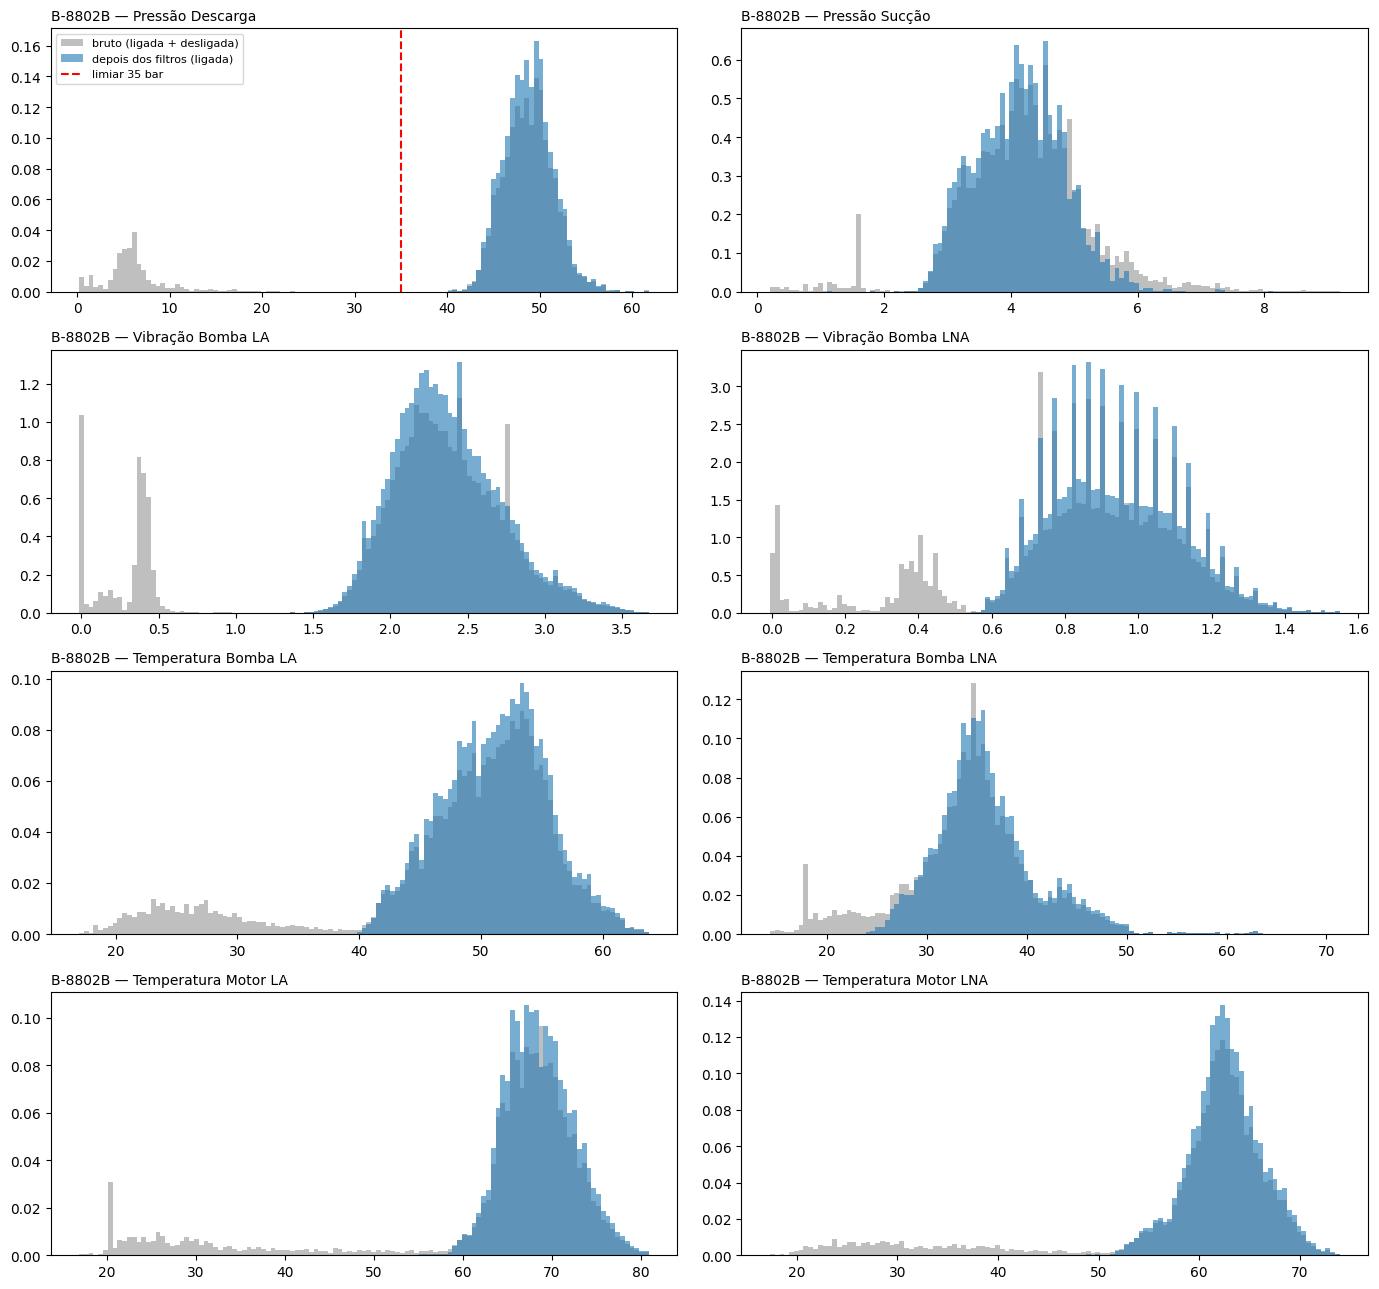

In [4]:
fig, axs = plt.subplots(4, 2, figsize=(14, 13))
for ax, c in zip(axs.flat, SENS):
    lo, hi = raw[c].quantile([.0005, .9995]); b = np.linspace(lo, hi, 120)
    ax.hist(raw[c], bins=b, color="gray", alpha=.5, density=True, label="bruto (ligada + desligada)")
    ax.hist(filt[c], bins=b, color="tab:blue", alpha=.6, density=True, label="depois dos filtros (ligada)")
    ax.set_title(f"{EQUIP} — {c}", fontsize=10, loc="left")
axs[0, 0].axvline(35, color="red", ls="--", label="limiar 35 bar"); axs[0, 0].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Leitura:**
- No bruto, a **parada** aparece como um segundo grupo em todos os sensores: vibração perto de 0 a 0,5 e temperaturas de 15 a 40 °C, esfriando.
- Depois do filtro, esse grupo some por completo: nenhum ponto com vibração LA abaixo de 0,5 nem com mancal LA abaixo de 35 °C.
- Com a bomba ligada, as pressões e as vibrações têm **uma distribuição só**. Não há sinal de duas fases operacionais.
- **A exceção é a temperatura do mancal LNA da bomba**: tem um grupo principal perto de 35 °C e um segundo, menor, perto de 43–47 °C. A seção 3 mostra de onde ele vem.

## 3. Só a bomba ligada, separado por período

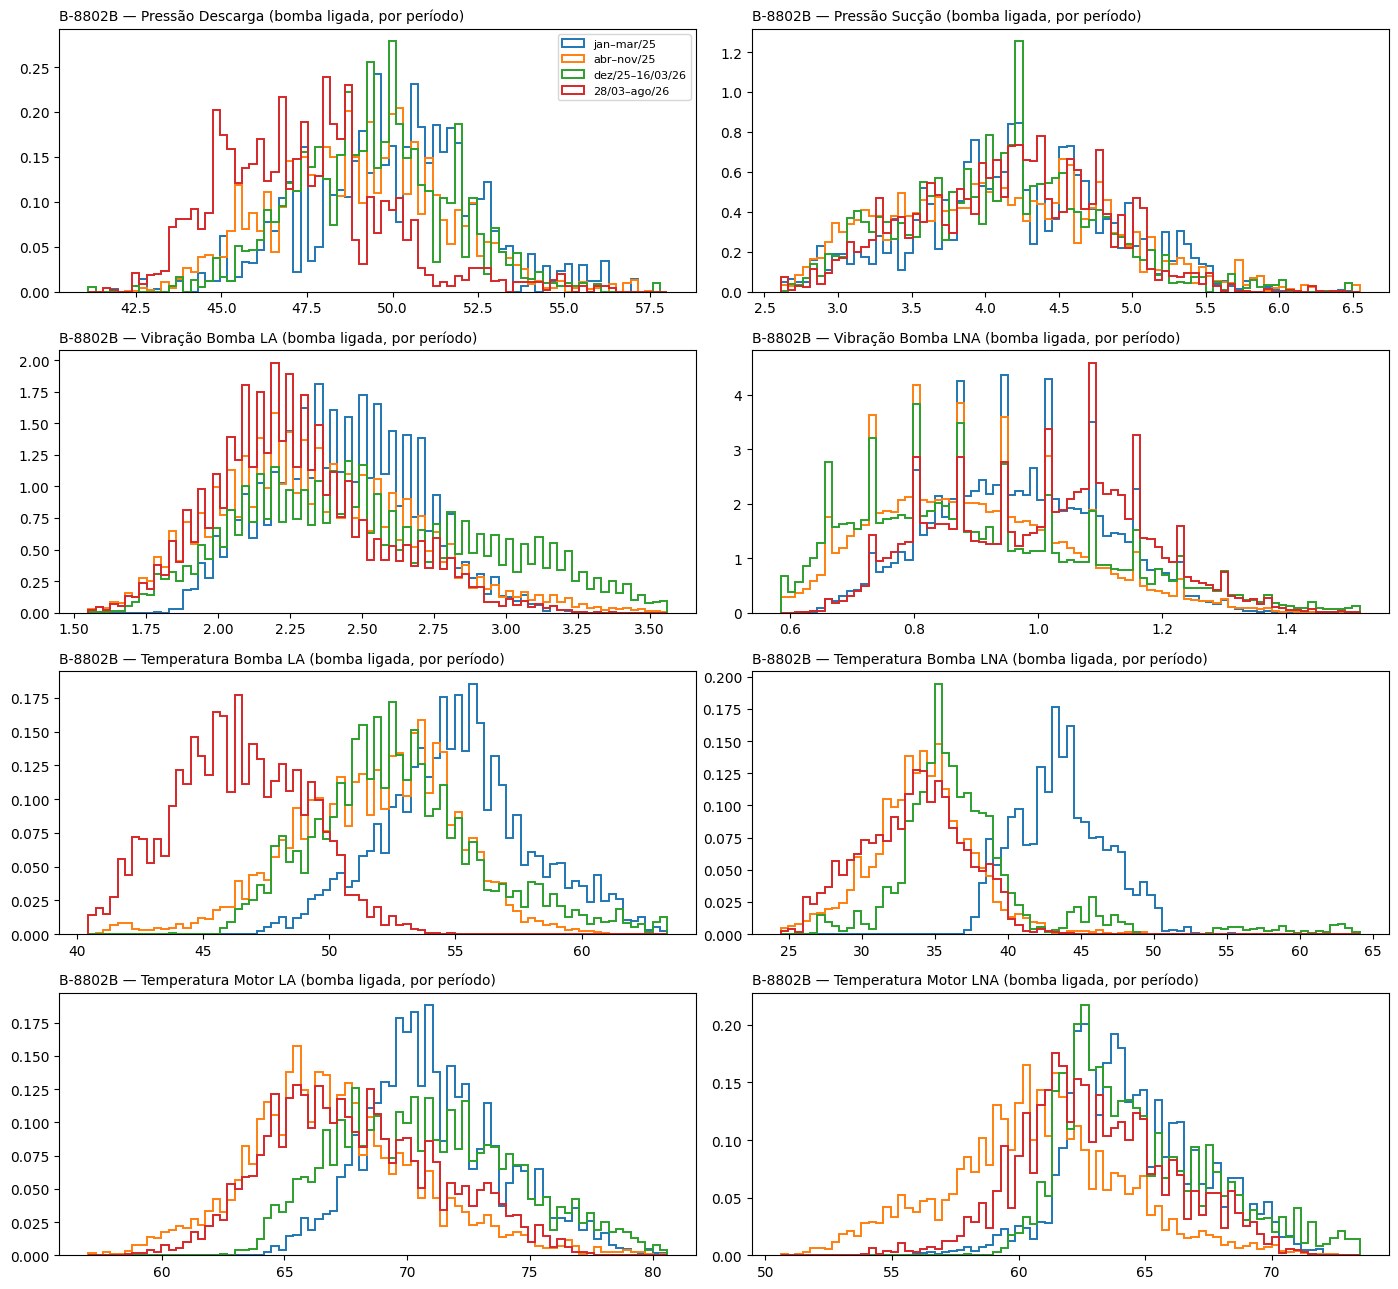

,Pressão Descarga,Pressão Sucção,Vibração Bomba LA,Vibração Bomba LNA,Temperatura Bomba LA,Temperatura Bomba LNA,Temperatura Motor LA,Temperatura Motor LNA
jan–mar/25,50.0,4.2,2.4,1.0,55.1,43.6,70.8,64.2
abr–nov/25,49.1,4.1,2.3,0.9,52.1,34.1,66.7,60.6
dez/25–16/03/26,49.3,4.1,2.5,0.9,52.8,36.3,70.7,64.0
28/03–ago/26,47.2,4.2,2.2,1.0,46.4,33.7,67.5,62.8


In [5]:
PER = {"jan–mar/25": ("2025-01-01", "2025-03-31"), "abr–nov/25": ("2025-04-01", "2025-11-30"),
       "dez/25–16/03/26": ("2025-12-01", "2026-03-16"), "28/03–ago/26": ("2026-03-28", "2026-08-10")}
fig, axs = plt.subplots(4, 2, figsize=(14, 13))
for ax, c in zip(axs.flat, SENS):
    lo, hi = filt[c].quantile([.001, .999]); b = np.linspace(lo, hi, 80)
    for n, (a, z) in PER.items():
        ax.hist(filt.loc[a:z, c], bins=b, histtype="step", lw=1.4, density=True, label=n)
    ax.set_title(f"{EQUIP} — {c} (bomba ligada, por período)", fontsize=10, loc="left")
axs[0, 0].legend(fontsize=8); fig.tight_layout(); plt.show()
filt[SENS].groupby(pd.cut(filt.index, [pd.Timestamp(a) for a, _ in PER.values()] + [pd.Timestamp("2026-08-11")],
                          labels=list(PER), right=False), observed=True).median().round(1)

**Leitura:**
- **Os dois grupos do mancal LNA são dois períodos, não duas fases de operação.** O grupo de 43–47 °C é só jan–mar/2025; de abril/2025 em diante, o mancal opera perto de 35 °C. É um patamar que mudou e ficou.
- **O mancal LA da bomba** tem um patamar por período: 55 °C (jan–mar/25), cerca de 52 °C (abr/25 a mar/26) e **cerca de 46 °C depois de 28/03/2026**. A curva vermelha fica quase toda abaixo das outras.
- **As temperaturas do motor** mudam com a estação (mais frias em abr–nov), mas não têm degrau.
- **As pressões** são parecidas em todos os períodos. A descarga de 2026 está 1 a 2 bar mais baixa.
- **A vibração LA** de dez/25 a mar/26 tem cauda mais longa (até 3,5).

**Resumo:** o filtro de bomba ligada está correto e a operação ligada tem **uma fase só**. As distribuições "duplas" que aparecem são de **tempo**: o patamar de temperatura dos mancais da bomba mudou em abr/2025 (LNA) e em 28/03/2026 (LA).

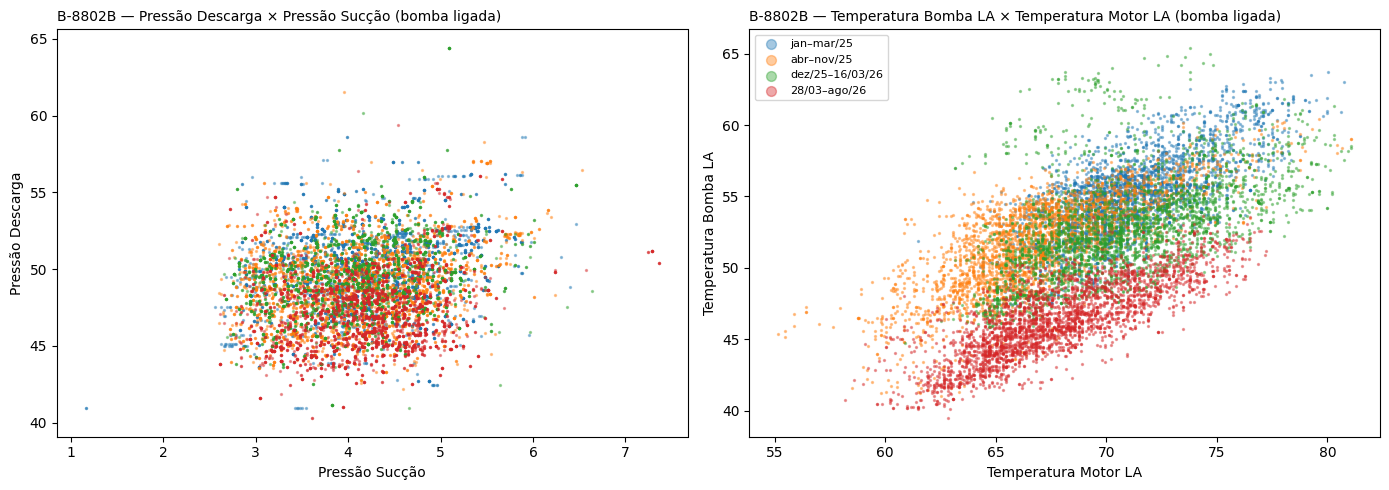

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, (xc, yc) in zip(axs, (("Pressão Sucção", "Pressão Descarga"), ("Temperatura Motor LA", "Temperatura Bomba LA"))):
    for n, (a, z) in PER.items():
        d = filt.loc[a:z].sample(min(3000, len(filt.loc[a:z])), random_state=0)
        ax.scatter(d[xc], d[yc], s=2, alpha=.4, label=n)
    ax.set_xlabel(xc); ax.set_ylabel(yc)
    ax.set_title(f"{EQUIP} — {yc} × {xc} (bomba ligada)", fontsize=10, loc="left")
axs[1].legend(markerscale=5, fontsize=8); fig.tight_layout(); plt.show()

- **Pressões:** uma nuvem só, sem grupos separados, ou seja, sem regimes de operação distintos.
- **Mancal LA da bomba × mancal LA do motor:** a relação é a mesma reta em todos os períodos, mas a nuvem de 28/03/2026 em diante está **deslocada cerca de 6 °C para baixo**. Para o mesmo motor, o mancal da bomba está mais frio. É isso que a diferença bomba − motor mede, e é a entrada testada no modelo novo.